In [4]:
# After you run this it'll say you have to restart session. Do that and then comment out this
# %pip install "vllm==0.33.0" peft transformers safetensors pandas matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.4/336.4 MB 63.8 MB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 119.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 MB 184.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.0/556.0 kB 28.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 148.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 144.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 96.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 MB 172.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.0/92.0 MB 171.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 46.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 126.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 196.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6/729.6 kB 45.3 MB/s  0:00:00
   ━━━

In [1]:
!nvidia-smi

Mon Nov  2 20:51:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   41C    P8             13W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os

# Required for this notebook's custom worker instrumentation.
os.environ["VLLM_ALLOW_INSECURE_SERIALIZATION"] = "1"

In [3]:
import torch
import vllm
import transformers
from peft import LoraConfig, get_peft_model

print("PyTorch:", torch.__version__)
print("vLLM:", vllm.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cu130
vLLM: 0.33.0
Transformers: 5.20.2
CUDA available: True
GPU: NVIDIA L4


In [4]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [5]:
import sys, os, json, time, random, platform, hashlib, subprocess, importlib.metadata
from pathlib import Path
from collections import OrderedDict, deque
from dataclasses import dataclass, asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from IPython.display import display

RUN_GPU = True
PROFILE = 'quick'  # quick: 3 seeds, 160 requests; full: 5 seeds, 800 requests
MODEL_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
N_ADAPTERS, RANK = 8, 8
SEEDS = [11] if PROFILE == 'quick' else [11, 22, 33, 44, 55]
N_REQUESTS = 60 if PROFILE == 'quick' else 800
ROOT = Path('/content/lora_cache_project') if Path('/content').exists() else Path.cwd()/'lora_cache_project'
ROOT.mkdir(parents=True, exist_ok=True)
for folder in ['traces','simulation','gpu','figures']:
    (ROOT/folder).mkdir(exist_ok=True)
random.seed(42); np.random.seed(42)

@dataclass(frozen=True)
class PolicyConfig:
    horizon_s: float = 1.0
    alpha: float = 0.12
    smoothing: float = 0.5
    min_history: int = 12
    min_probability: float = 0.55
    budget_per_window: int = 1
    window_s: float = 1.0
    bandwidth_price: float = 0.25  # transfer seconds converted to latency penalty
    safety_margin_s: float = 0.00005

CFG = PolicyConfig()
POLICIES = ['lru', 'ewma', 'transition', 'logistic',
            'ewma_cost', 'transition_cost', 'logistic_cost']
# Assumptions only; GPU calibration replaces these for GPU admission decisions.
SIM_LOAD_S, SIM_FIRST_S, SIM_RESPONSE_S = 0.004, 0.025, 0.08
SIM_BYTES = np.full(N_ADAPTERS, 1024*1024, dtype=np.int64)
print('Outputs:', ROOT, '| GPU enabled:', RUN_GPU)

Outputs: /content/lora_cache_project | GPU enabled: True


In [6]:
# from google.colab import drive
# from pathlib import Path
# import shutil

# drive.mount("/content/drive")

# checkpoint = Path("/content/drive/MyDrive/LoRA_Cache_Project/checkpoint")
# shutil.copytree(checkpoint, ROOT, dirs_exist_ok=True)

In [7]:
def make_trace(n=160, adapters=8, rate=3.0, seed=11, skew=1.2,
               locality=0.0, burst_factor=1.0, drift_severity=0.0,
               drift_width=0, cycle_probability=0.0):
    assert n > 0 and adapters > 0 and rate > 0 and skew >= 0
    assert 0 <= locality <= 1 and 0 <= drift_severity <= 1
    assert 0 <= cycle_probability <= 1 and burst_factor >= 1
    rng_a, rng_t = [np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(2)]
    base = (np.arange(adapters)+1.)**(-skew); base /= base.sum()
    drift_idx = n//2 if drift_severity else None
    t, prev, rows = 0., None, []
    for k in range(n):
        u = 0. if drift_idx is None or k < drift_idx else (1. if drift_width == 0 else min(1., (k-drift_idx+1)/drift_width))
        mix = drift_severity*u
        p = (1-mix)*base + mix*base[::-1]
        # Always draw the same number of identity RNG values per request.
        choice, keep, cycle = rng_a.choice(adapters, p=p), rng_a.random(), rng_a.random()
        a = int(choice)
        if prev is not None:
            if keep < locality: a = prev
            elif cycle < cycle_probability: a = (prev+1)%adapters
        r = rate*(burst_factor if n//3 <= k < n//2 else 1.)
        t += rng_t.exponential(1/r)
        rows.append(dict(request_id=k, timestamp_s=t, adapter=a, phase='post' if drift_idx is not None and k>=drift_idx else 'pre'))
        prev = a
    return pd.DataFrame(rows)

SCENARIOS = {
    'control': {}, 'uniform': {'skew':0.0}, 'skewed': {'skew':2.0},
    'burst5': {'burst_factor':5.0}, 'burst15': {'burst_factor':15.0},
    'rate_low': {'rate':1.0}, 'rate_high': {'rate':10.0},
    'locality': {'locality':0.8}, 'cycle': {'skew':0.0, 'cycle_probability':0.9},
    'drift_mild': {'drift_severity':0.4},
    'drift_abrupt': {'drift_severity':1.0},
    'drift_gradual': {'drift_severity':1.0, 'drift_width':N_REQUESTS//4},
    'burst_drift': {'burst_factor':5., 'drift_severity':1.0},
}
CAPACITIES = [2]
# Traces are generated once and shared verbatim by all policies/backends.
TRACES = {}
for scenario, kw in SCENARIOS.items():
    for seed in SEEDS:
        tr = make_trace(n=N_REQUESTS, adapters=N_ADAPTERS, seed=seed, **kw)
        TRACES[scenario, seed] = tr
        tr.to_csv(ROOT/'traces'/f'{scenario}_{seed}.csv', index=False)
display(TRACES['control', SEEDS[0]].head())

,request_id,timestamp_s,adapter,phase
0,0,0.284251,5,pre
1,1,0.637198,0,pre
2,2,1.238671,0,pre
3,3,1.766791,3,pre
4,4,1.918321,5,pre


In [8]:
class Predictor:
    def __init__(self, kind, n, cfg=CFG, seed=42):
        self.kind, self.n, self.cfg = kind, n, cfg
        self.share = np.full(n, 1/n); self.delta = np.zeros(n)
        self.last_seen = np.full(n, np.nan)
        self.transitions = np.full((n,n), cfg.smoothing)
        self.prev = None; self.n_seen = 0; self.start = None; self.now = 0.
        self.pending = deque(); self.trained = False; self.training_windows = 0
        self.clf = SGDClassifier(loss='log_loss', learning_rate='constant', eta0=0.03,
                                 alpha=0.0001, random_state=seed)
    def features(self, t):
        recency = np.where(np.isnan(self.last_seen), 10., np.minimum(10., np.maximum(0.,t-self.last_seen)/self.cfg.horizon_s))
        trans = self.transition_share()
        return np.column_stack([np.eye(self.n), self.share, recency/10., self.delta, trans])
    def transition_share(self):
        if self.prev is None: return self.share.copy()
        row = self.transitions[self.prev]
        return row/row.sum()
    def mature(self, t):
        # Run before marking a new observation; equality belongs to the old window.
        while self.pending and self.pending[0][0] < t:
            deadline, X, y = self.pending.popleft()
            self.clf.partial_fit(X, y, classes=np.array([0,1]))
            self.trained = True; self.training_windows += 1
    def observe(self, a, t):
        assert t >= self.now
        self.mature(t)
        for deadline, X, y in self.pending:
            if t <= deadline: y[a] = 1
        old = self.share.copy()
        self.share *= 1-self.cfg.alpha; self.share[a] += self.cfg.alpha
        self.delta = self.share-old
        self.transitions = self.cfg.smoothing + (self.transitions-self.cfg.smoothing)*(1-self.cfg.alpha)
        if self.prev is not None: self.transitions[self.prev,a] += 1
        self.prev = int(a); self.last_seen[a] = t
        self.start = t if self.start is None else self.start
        self.n_seen += 1; self.now = t
        if self.kind == 'logistic':
            self.pending.append((t+self.cfg.horizon_s, self.features(t).copy(), np.zeros(self.n,dtype=int)))
    def predict(self, t):
        # Maturation occurs on observe, avoiding premature labels during idle time.
        if self.kind == 'logistic' and self.trained:
            return np.clip(self.clf.predict_proba(self.features(t))[:,1],0.,1.)
        q = self.transition_share() if self.kind == 'transition' else self.share
        elapsed = max(self.cfg.horizon_s, self.now-(self.start or 0.))
        rate = max(0.01, (self.n_seen-1)/elapsed)
        return -np.expm1(-rate*self.cfg.horizon_s*q)

class Controller:
    def __init__(self, policy, n, cfg=CFG):
        assert policy in POLICIES
        self.policy, self.cfg = policy, cfg
        self.predictor = Predictor(policy.split('_')[0], n, cfg)
        self.bucket = None; self.used = 0; self.logs = []
    def observe(self, a, t): self.predictor.observe(a,t)
    def choose(self, t, lru_order, capacity, costs, sizes):
        if self.policy == 'lru' or self.predictor.n_seen < self.cfg.min_history: return None
        bucket = int(t//self.cfg.window_s)
        if bucket != self.bucket: self.bucket, self.used = bucket, 0
        if self.used >= self.cfg.budget_per_window: return None
        p = self.predictor.predict(t)
        ranking = np.argsort(-p, kind='stable')
        a = next((int(x) for x in ranking if int(x) not in lru_order),None)
        if a is None: return None
        victim = lru_order[0] if len(lru_order)>=capacity else None
        # Relative byte sizes account for heterogeneous adapters if later enabled.
        penalty = costs[a]*self.cfg.bandwidth_price
        eviction_cost = 0. if victim is None else p[victim]*costs[victim]
        benefit = p[a]*costs[a]
        cost = (1-p[a])*penalty + eviction_cost + self.cfg.safety_margin_s
        admitted = not self.policy.endswith('_cost') or (p[a]>=self.cfg.min_probability and benefit>cost)
        self.logs.append(dict(time_s=t, candidate=a, probability=float(p[a]),
                              victim= victim, expected_benefit_s=benefit,
                              expected_cost_s=cost, admitted=bool(admitted)))
        if admitted: self.used += 1; return a
        return None

In [9]:
class CacheLedger:
    def __init__(self, capacity, sizes):
        assert capacity>0
        self.capacity=capacity; self.sizes=np.asarray(sizes)
        self.items=OrderedDict(); self.speculative=set(); self.events=[]
        self.useful=0; self.wasted=0; self.prefetches=0; self.transfers=0; self.evictions=0
    def demand(self, a):
        hit = a in self.items
        if hit:
            if a in self.speculative: self.speculative.remove(a); self.useful+=1
            self.items.move_to_end(a)
        return hit
    def load(self, a, t, prefetch=False):
        if a in self.items: return
        victim=None
        if len(self.items)>=self.capacity:
            victim,_=self.items.popitem(last=False); self.evictions+=1
            if victim in self.speculative:
                self.speculative.remove(victim); self.wasted+=int(self.sizes[victim])
        self.items[a]=None
        if prefetch: self.speculative.add(a); self.prefetches+=1
        self.transfers+=int(self.sizes[a])
        self.events.append(dict(time_s=t, adapter=a, prefetch=prefetch,
                                victim=victim, payload_bytes=int(self.sizes[a])))
    def final(self):
        pending_bytes=int(sum(self.sizes[a] for a in self.speculative))
        return dict(prefetches=self.prefetches, useful_prefetches=self.useful,
                    useful_prefetch_rate=self.useful/self.prefetches if self.prefetches else np.nan,
                    wasted_bytes_evicted=self.wasted, unused_bytes_end=pending_bytes,
                    wasted_bytes_total=self.wasted+pending_bytes,
                    transfer_bytes=self.transfers, evictions=self.evictions)

def summarize_requests(df):
    return dict(requests=len(df), hit_rate=float(df.hit.mean()), miss_rate=float(1-df.hit.mean()),
                ttft_p50_s=float(df.ttft_s.quantile(.5)), ttft_p95_s=float(df.ttft_s.quantile(.95)),
                ttft_p99_s=float(df.ttft_s.quantile(.99)),
                mean_queue_s=float(df.queue_s.mean()))

def simulate(tr, policy='lru', capacity=2, costs=None, sizes=SIM_BYTES, cfg=CFG):
    costs=np.full(N_ADAPTERS,SIM_LOAD_S) if costs is None else np.asarray(costs)
    cache=CacheLedger(capacity,sizes); ctrl=Controller(policy,N_ADAPTERS,cfg)
    free=0.; rows=[]
    for r in tr.itertuples(index=False):
        dispatch=max(float(r.timestamp_s),free)
        hit=cache.demand(r.adapter)
        load=0. if hit else costs[r.adapter]
        if not hit: cache.load(r.adapter,dispatch+load)
        first=dispatch+load+SIM_FIRST_S
        free=dispatch+load+SIM_RESPONSE_S
        ctrl.observe(r.adapter,dispatch)
        a=ctrl.choose(free,list(cache.items),capacity,costs,sizes)
        if a is not None:
            free+=costs[a]; cache.load(a,free,prefetch=True)
        rows.append(dict(request_id=r.request_id, adapter=r.adapter, timestamp_s=r.timestamp_s,
                         phase=r.phase, hit=hit, queue_s=dispatch-r.timestamp_s,
                         ttft_s=first-r.timestamp_s, service_ttft_s=first-dispatch))
    df=pd.DataFrame(rows)
    stats=dict(backend='simulation', policy=policy, capacity=capacity,
               **summarize_requests(df), **cache.final())
    return stats,df,pd.DataFrame(cache.events),pd.DataFrame(ctrl.logs)

In [10]:
def run_checks():
    c=CacheLedger(2,[10,20,30]); c.load(0,0); c.load(1,0)
    assert c.demand(0); c.load(2,1,prefetch=True)
    assert list(c.items)==[0,2] and c.evictions==1
    assert c.demand(2) and c.useful==1
    c.load(1,2,prefetch=True); c.load(0,3); c.load(2,4)
    assert c.final()['wasted_bytes_evicted']==20
    p=Predictor('logistic',3,replace(CFG,horizon_s=1.))
    p.observe(0,0.); p.observe(1,.5)
    assert not p.trained and p.pending[0][2].tolist()==[0,1,0]
    p.observe(2,1.1)
    assert p.training_windows==1 and np.isfinite(p.predict(1.1)).all()
    p1=Predictor('logistic',3); p2=Predictor('logistic',3)
    for a,t in [(0,0.),(1,.2),(0,.7),(2,1.4)]:
        p1.observe(a,t); p2.observe(a,t)
        assert np.allclose(p1.predict(t),p2.predict(t))
    a=make_trace(seed=99); b=make_trace(seed=99,burst_factor=10)
    assert a.adapter.equals(b.adapter) and not a.timestamp_s.equals(b.timestamp_s)
    full=simulate(a,'lru',N_ADAPTERS)[0]
    assert round(full['miss_rate']*len(a))==a.adapter.nunique()
    for policy in POLICIES:
        st,df,ev,_=simulate(a,policy,2)
        assert df.ttft_s.ge(SIM_FIRST_S-1e-9).all()
        assert st['transfer_bytes']==ev.payload_bytes.sum()
        assert st['useful_prefetches']<=st['prefetches']
        assert st['transfer_bytes']>=st['wasted_bytes_total']
    # A prefetch occupies the serial resource before the next demand can start.
    tiny=pd.DataFrame(dict(request_id=[0,1],timestamp_s=[0.,.001],adapter=[0,0],phase=['pre','pre']))
    _,reactive,_,_=simulate(tiny,'lru',capacity=1)
    _,speculative,_,_=simulate(tiny,'ewma',capacity=1,
                              cfg=replace(CFG,min_history=1,window_s=.0001))
    assert speculative.queue_s.iloc[1] >= reactive.queue_s.iloc[1]+SIM_LOAD_S-1e-9
    print('All CPU correctness checks passed.')
run_checks()

All CPU correctness checks passed.


In [11]:
# Independent runs: new cache and predictor for every seed/policy/capacity.
sim_rows=[]
for (scenario,seed),tr in TRACES.items():
    for cap in CAPACITIES:
        for policy in POLICIES:
            stats,requests,events,decisions=simulate(tr,policy,cap)
            stem=f'{scenario}_s{seed}_c{cap}_{policy}'
            sim_rows.append(dict(scenario=scenario,seed=seed,**stats))
            requests.to_csv(ROOT/'simulation'/f'{stem}_requests.csv',index=False)
            events.to_csv(ROOT/'simulation'/f'{stem}_events.csv',index=False)
            decisions.to_csv(ROOT/'simulation'/f'{stem}_decisions.csv',index=False)
sim_results=pd.DataFrame(sim_rows)
sim_results.to_csv(ROOT/'simulation'/'summary.csv',index=False)
display(sim_results.groupby(['scenario','capacity','policy'])[
    ['hit_rate','ttft_p95_s','wasted_bytes_total','evictions']].mean().round(4))

hit_rate  ttft_p95_s  wasted_bytes_total  \
scenario capacity policy                                                      
burst15  2        ewma               0.4167      0.5764           9437184.0   
                  ewma_cost          0.4333      0.5802           3145728.0   
                  logistic           0.4500      0.5724           7340032.0   
                  logistic_cost      0.3833      0.5764                 0.0   
                  lru                0.3833      0.5764                 0.0   
...                                     ...         ...                 ...   
uniform  2        logistic           0.1833      0.0898          12582912.0   
                  logistic_cost      0.1333      0.0871                 0.0   
                  lru                0.1333      0.0871                 0.0   
                  transition         0.1000      0.0900          17825792.0   
                  transition_cost    0.1167      0.0871           2097152.0   

                                   evictions  
scenario capacity policy                      
burst15  2        ewma                  48.0  
                  ewma_cost             40.0  
                  logistic              46.0  
                  logistic_cost         35.0  
                  lru                   35.0  
...                                      ...  
uniform  2        logistic              64.0  
                  logistic_cost         50.0  
                  lru                   50.0  
                  transition            69.0  
                  transition_cost       53.0  

[91 rows x 4 columns]

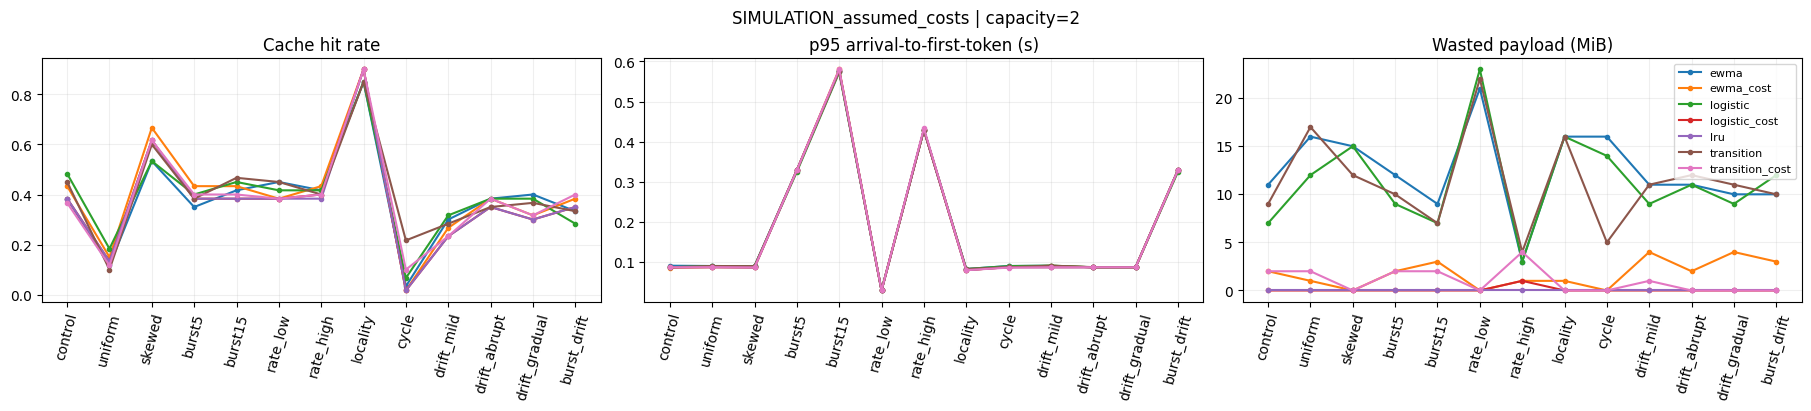

In [12]:
def paired_comparisons(results, metric='ttft_p95_s'):
    keys=['scenario','seed','capacity']
    baseline=results[results.policy=='lru'][keys+[metric]].rename(columns={metric:'lru_value'})
    paired=results.merge(baseline,on=keys,validate='many_to_one')
    paired['delta']=paired[metric]-paired.lru_value
    paired['relative_percent']=100*paired['delta']/paired.lru_value.replace(0,np.nan)
    rows=[]; rng=np.random.default_rng(123)
    for key,g in paired.groupby(['scenario','capacity','policy']):
        vals=g.delta.to_numpy(); boots=rng.choice(vals,(2000,len(vals)),replace=True).mean(axis=1)
        rows.append(dict(zip(['scenario','capacity','policy'],key), metric=metric,n_seeds=len(vals),
                         mean_delta=vals.mean(),ci_low=np.quantile(boots,.025),ci_high=np.quantile(boots,.975),
                         mean_relative_percent=g.relative_percent.mean()))
    return pd.DataFrame(rows)

def drift_recovery(requests, tr, width=0, block=20, tolerance=.10):
    idx=len(tr)//2+max(0,width-1)
    if idx>=len(tr): return dict(recovery_s=np.nan, reference_miss_rate=np.nan)
    reference=1-requests.hit.tail(min(60,len(requests)//3)).mean()
    post=requests[requests.request_id>=idx]
    windows=[post.iloc[i:i+block] for i in range(0,len(post)-block+1,block)]
    ok=[abs((1-w.hit.mean())-reference)<=tolerance for w in windows]
    recovery=np.nan
    for i in range(max(0,len(ok)-2)):
        if all(ok[i:i+3]):
            recovery=float(windows[i].timestamp_s.iloc[0]-tr.timestamp_s.iloc[idx]); break
    return dict(recovery_s=recovery,reference_miss_rate=float(reference))

sim_pairs=paired_comparisons(sim_results)
sim_pairs.to_csv(ROOT/'simulation'/'paired_p95.csv',index=False)
recovery_rows=[]
for (scenario,seed),tr in TRACES.items():
    if not SCENARIOS[scenario].get('drift_severity'): continue
    for cap in CAPACITIES:
        for policy in POLICIES:
            path=ROOT/'simulation'/f'{scenario}_s{seed}_c{cap}_{policy}_requests.csv'
            recovery_rows.append(dict(scenario=scenario,seed=seed,capacity=cap,policy=policy,
                **drift_recovery(pd.read_csv(path),tr,SCENARIOS[scenario].get('drift_width',0))))
pd.DataFrame(recovery_rows).to_csv(ROOT/'simulation'/'drift_recovery.csv',index=False)

def plot_results(results, label, folder):
    for cap in sorted(results.capacity.unique()):
        subset=results[results.capacity==cap]
        scenarios=list(subset.scenario.unique())
        fig,axes=plt.subplots(1,3,figsize=(18,4),layout='constrained')
        for ax,metric,title in zip(axes,['hit_rate','ttft_p95_s','wasted_bytes_total'],
                                  ['Cache hit rate','p95 arrival-to-first-token (s)','Wasted payload (MiB)']):
            for policy,g in subset.groupby('policy'):
                means=g.groupby('scenario')[metric].mean().reindex(scenarios)
                if metric=='wasted_bytes_total': means=means/2**20
                ax.plot(scenarios,means,marker='.',label=policy)
            ax.set_title(title); ax.tick_params(axis='x',rotation=75); ax.grid(alpha=.2)
        axes[-1].legend(fontsize=8); fig.suptitle(f'{label} | capacity={cap}')
        fig.savefig(folder/f'{label}_capacity{cap}.png',dpi=160,bbox_inches='tight')
        plt.show()
plot_results(sim_results,'SIMULATION_assumed_costs',ROOT/'figures')

GPU

In [13]:
if RUN_GPU:
    import torch, gc, vllm
    assert torch.cuda.is_available(), 'Choose a GPU runtime.'
    assert vllm.__version__ == '0.33.0', f'Expected 0.33.0, found {vllm.__version__}. Revalidate the worker probe before changing this guard.'
    manifest=dict(python=sys.version,platform=platform.platform(),model=MODEL_ID,
                  n_adapters=N_ADAPTERS,rank=RANK,profile=PROFILE,
                  gpu=torch.cuda.get_device_name(0),torch=torch.__version__,
                  cuda=torch.version.cuda,vllm=vllm.__version__,
                  gpu_total_bytes=torch.cuda.get_device_properties(0).total_memory,
                  policy_config=asdict(CFG),seeds=SEEDS,scenarios=SCENARIOS,
                  concurrency=1,prompt_tokens=64,output_tokens=16,
                  gpu_memory_utilization=.75,enforce_eager=True,prefix_caching=False)
    (ROOT/'environment.json').write_text(json.dumps(manifest,indent=2))
    (ROOT/'requirements_frozen.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
    try:
        (ROOT/'nvidia_smi.txt').write_text(subprocess.check_output(['nvidia-smi'],text=True))
    except FileNotFoundError: pass
    from transformers import AutoModelForCausalLM, AutoTokenizer
    from peft import LoraConfig, get_peft_model
    adapter_root=ROOT/'adapters'/MODEL_ID.replace('/','_')/f'rank{RANK}'
    paths=[adapter_root/f'adapter_{i:02d}' for i in range(N_ADAPTERS)]
    signature=dict(model=MODEL_ID,rank=RANK,n=N_ADAPTERS,targets=['q_proj','v_proj'],seed=42)
    signature_path=adapter_root/'manifest.json'
    valid=signature_path.exists() and json.loads(signature_path.read_text())==signature
    valid=valid and all((p/'adapter_model.safetensors').exists() and (p/'adapter_config.json').exists() for p in paths)
    if not valid:
        base=AutoModelForCausalLM.from_pretrained(MODEL_ID,torch_dtype=torch.float32,low_cpu_mem_usage=True)
        model=get_peft_model(base,LoraConfig(r=RANK,lora_alpha=16,target_modules=['q_proj','v_proj'],
                                            lora_dropout=0.,bias='none',task_type='CAUSAL_LM'))
        for i,path in enumerate(paths):
            torch.manual_seed(42+i)
            with torch.no_grad():
                for name,param in model.named_parameters():
                    if 'lora_A' in name or 'lora_B' in name: torch.nn.init.normal_(param,0.,.01)
            path.mkdir(parents=True,exist_ok=True); model.save_pretrained(str(path),safe_serialization=True)
        signature_path.write_text(json.dumps(signature,indent=2))
        del model,base; gc.collect()
    print('Adapter artifacts ready:',adapter_root)
else:
    print('GPU setup skipped. Set RUN_GPU=True and restart/run all on a GPU to measure serving.')

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Adapter artifacts ready: /content/lora_cache_project/adapters/Qwen_Qwen2.5-1.5B-Instruct/rank8


In [14]:
def worker_probe(worker, mode='snapshot', adapter_id=None):
    """Self-contained callable serialized into the vLLM worker; no notebook globals."""
    import time
    import torch
    runner=getattr(worker,'model_runner',None)
    wm=getattr(runner,'lora_manager',None)
    manager=getattr(wm,'_adapter_manager',None)
    if manager is None:
        raise RuntimeError('Cannot locate model_runner.lora_manager._adapter_manager; inspect this vLLM version.')
    if 'LRUCache' not in type(manager).__name__:
        raise RuntimeError('Expected the native LRU LoRA model manager.')
    for attr in ['_active_adapters','_registered_adapters','lora_index_to_id']:
        if not hasattr(manager,attr): raise RuntimeError('Missing vLLM instrumentation field: '+attr)
    def order():
        cache=getattr(manager._active_adapters,'cache',None)
        if cache is None: raise RuntimeError('GPU LRU order is unavailable.')
        return [int(x) for x in cache.keys()]
    def tensor_bytes(obj):
        if torch.is_tensor(obj): return obj.numel()*obj.element_size()
        if isinstance(obj,(list,tuple)): return sum(tensor_bytes(x) for x in obj)
        if isinstance(obj,dict): return sum(tensor_bytes(x) for x in obj.values())
        return 0
    def payload(a):
        model=manager._registered_adapters.cache[a]
        return sum(tensor_bytes(getattr(weights,'lora_a',None))+tensor_bytes(getattr(weights,'lora_b',None))
                   for weights in model.loras.values())
    if not hasattr(manager,'_project_events'):
        manager._project_events=[]; manager._project_phase='demand'
        original=manager.activate_adapter
        def tracked(a):
            before=order(); start=time.perf_counter()
            result=original(a)
            after=order()
            if a not in before:
                manager._project_events.append(dict(adapter_id=int(a),phase=manager._project_phase,
                    worker_start_s=start,worker_end_s=time.perf_counter(),
                    activation_call_s=time.perf_counter()-start,
                    evicted_ids=[x for x in before if x not in after],
                    payload_bytes=int(payload(a)),resident_ids=after))
            return result
        manager.activate_adapter=tracked
    if mode=='reset':
        for a in list(order()): manager.deactivate_adapter(a)
        manager._last_mapping=None
        if hasattr(manager,'_last_slot_layout'): manager._last_slot_layout=None
        manager._project_events=[]; manager._project_phase='demand'
        torch.cuda.synchronize()
    elif mode=='prefetch':
        if adapter_id not in manager._registered_adapters.cache: raise RuntimeError('Adapter not CPU-resident.')
        manager._project_phase='prefetch'
        try:
            torch.cuda.synchronize(); t=time.perf_counter()
            manager.activate_adapter(adapter_id)
            torch.cuda.synchronize()
            elapsed=time.perf_counter()-t
            # Force mapping metadata refresh after out-of-band activation.
            manager._last_mapping=None
            if hasattr(manager,'_last_slot_layout'): manager._last_slot_layout=None
        finally: manager._project_phase='demand'
    elif mode not in ('snapshot','install'):
        raise ValueError(mode)
    out=dict(gpu_order_ids=order(),cpu_ids=[int(x) for x in manager._registered_adapters.cache.keys()],
             capacity=int(manager.lora_slots),manager_type=type(manager).__name__,
             events=list(manager._project_events),
             payload_bytes={int(a):int(payload(a)) for a in manager._registered_adapters.cache.keys()})
    if mode=='prefetch': out['synchronized_activation_s']=elapsed
    manager._project_events=[]
    return out

In [15]:
if RUN_GPU:
    import asyncio, inspect
    from vllm import AsyncEngineArgs, SamplingParams
    from vllm.v1.engine.async_llm import AsyncLLM
    from vllm.lora.request import LoRARequest
    from vllm.sampling_params import RequestOutputKind
    tokenizer=AutoTokenizer.from_pretrained(MODEL_ID)
    # A fixed tokenized input controls token count across policies and adapters.
    ids=tokenizer.encode('Explain how CPU and GPU memory differ. ',add_special_tokens=False)
    PROMPT={'prompt_token_ids':(ids*64)[:64]}
    SAMPLING=SamplingParams(temperature=0.,max_tokens=16,min_tokens=16,
                            ignore_eos=True,output_kind=RequestOutputKind.CUMULATIVE)
    LORA_REQUESTS=[LoRARequest(f'adapter_{i:02d}',i+1,str(paths[i])) for i in range(N_ADAPTERS)]

async def rpc_one(engine, mode='snapshot', adapter_id=None):
    result=await engine.collective_rpc(worker_probe,args=(mode,adapter_id))
    if len(result)!=1: raise RuntimeError('This harness requires exactly one GPU worker.')
    return result[0]

async def consume(engine, adapter, request_id):
    submitted=time.perf_counter(); first=None; final=None
    async for out in engine.generate(PROMPT,SAMPLING,request_id=request_id,lora_request=LORA_REQUESTS[adapter]):
        final=out
        if first is None and out.outputs and out.outputs[0].token_ids:
            first=time.perf_counter()
    ended=time.perf_counter()
    if first is None: raise RuntimeError('No output token observed; TTFT cannot be measured.')
    return dict(submitted=submitted,first=first,ended=ended,
                output_tokens=len(final.outputs[0].token_ids))

async def start_engine(capacity):
    engine=AsyncLLM.from_engine_args(AsyncEngineArgs(
        model=MODEL_ID,enable_lora=True,max_loras=capacity,max_lora_rank=RANK,
        max_cpu_loras=N_ADAPTERS,max_model_len=256,gpu_memory_utilization=.75,
        dtype='float16',lora_dtype='float16',enforce_eager=True,
        enable_prefix_caching=False,max_num_seqs=1,seed=42,
        disable_log_stats=True))
    # Exclude startup, disk registration, and first generation/kernel warmup.
    for req in LORA_REQUESTS: await engine.add_lora(req)
    await rpc_one(engine,'install')
    for i in range(N_ADAPTERS): await consume(engine,i,f'warm_{capacity}_{i}')
    snapshot=await rpc_one(engine,'reset')
    assert len(snapshot['cpu_ids'])==N_ADAPTERS and snapshot['gpu_order_ids']==[]
    return engine

async def stop_engine(engine):
    result=engine.shutdown()
    if inspect.isawaitable(result): await result
    gc.collect(); torch.cuda.empty_cache()

async def calibrate(engine, repeats=5):
    records=[]
    for a in range(N_ADAPTERS):
        for k in range(repeats):
            await rpc_one(engine,'reset')
            t=time.perf_counter(); out=await rpc_one(engine,'prefetch',a+1)
            records.append(dict(adapter=a,repeat=k,
                activation_s=out['synchronized_activation_s'],
                rpc_wall_s=time.perf_counter()-t,payload_bytes=out['payload_bytes'][a+1]))
    await rpc_one(engine,'reset')
    df=pd.DataFrame(records)
    return df,df.groupby('adapter').activation_s.median().reindex(range(N_ADAPTERS)).to_numpy(),df.groupby('adapter').payload_bytes.first().reindex(range(N_ADAPTERS)).to_numpy()

async def gpu_preflight(engine,capacity):
    await rpc_one(engine,'reset')
    for a in range(capacity): await rpc_one(engine,'prefetch',a+1)
    # Touch adapter 1; native LRU should now evict adapter 2, not adapter 1.
    await rpc_one(engine,'prefetch',1)
    snapshot=await rpc_one(engine,'prefetch',capacity+1)
    assert 1 in snapshot['gpu_order_ids'] and 2 not in snapshot['gpu_order_ids']
    resident=capacity  # zero-based adapter just prefetched
    await consume(engine,resident,'preflight_hit')
    after=await rpc_one(engine)
    assert not any(e['adapter_id']==resident+1 for e in after['events']), 'GPU prefetch did not avoid activation.'
    assert len(after['cpu_ids'])==N_ADAPTERS, 'CPU library was evicted.'
    assert all(v>0 for v in after['payload_bytes'].values()), 'Tensor payload accounting failed.'
    await rpc_one(engine,'reset')
    print('GPU preflight passed: native LRU order, prefetch activation and CPU residency verified.')

W1102 20:53:06.794000 11510 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1102 20:53:06.795000 11510 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1102 20:53:06.797000 11510 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

(MainProcess pid=11510) INFO 11-02 20:53:31 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=11510) WARNING 11-02 20:53:31 [model.py:2516] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=11510) INFO 11-02 20:53:31 [model.py:2170] Using max model len 256
(MainProcess pid=11510) INFO 11-02 20:53:31 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=256.
(MainProcess pid=11510) WARNING 11-02 20:53:32 [vllm.py:1778] Enforce eager set, disabling torch.compile, CUDAGraphs, and JIT kernel warmup. This is equivalent to setting -cc.mode=none -cc.cudagraph_mode=none and --kernel_config.enable_jit_warmup=False
(MainProcess pid=11510) WARNING 11-02 20:53:32 [vllm.py:1802] Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
(MainProcess pid=11510) INFO 11-02 20:53:32 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(r

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

(MainProcess pid=11510) WARNING 11-02 20:53:36 [system_utils.py:154] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
(MainProcess pid=11510) WARNING 11-02 20:55:50 [serial_utils.py:78] Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(MainProcess pid=11510) WARNING 11-02 20:55:51 [input_processor.py:289] vLLM has deprecated support for supporting different tokenizers for different LoRAs. By default, vLLM uses base model's tokenizer. If you are using a LoRA with its own tokenizer, consider specifying `--tokenizer [lora_path]` to use the LoRA tokenizer.
(MainProcess pid=11510) WARNING 11-02 20:55:51 [input_processor.py:408] Passing raw prompts to InputProcessor is deprecated and will be removed in the future. You should instead pass the outputs of Renderer.re

,backend,policy,capacity,requests,hit_rate,miss_rate,ttft_p50_s,ttft_p95_s,ttft_p99_s,mean_queue_s,...,useful_prefetches,useful_prefetch_rate,wasted_bytes_evicted,unused_bytes_end,wasted_bytes_total,transfer_bytes,evictions,scenario,seed,fingerprint
0,gpu_single_flight,lru,2,60,0.383333,0.616667,24.747447,44.402561,46.370593,23.662293,...,0,NaN,0,0,0,80625664,35,control,11,5329ff4e55e220b04a3499547836d6988f32eb18619f69...
1,gpu_single_flight,logistic,2,60,0.416667,0.583333,24.971071,44.708392,46.679405,23.834998,...,9,0.183673,84983808,2179072,87162880,183042048,82,control,11,5329ff4e55e220b04a3499547836d6988f32eb18619f69...
2,gpu_single_flight,transition_cost,2,60,0.383333,0.616667,24.666901,44.041886,45.962620,23.519127,...,0,NaN,0,0,0,80625664,35,control,11,5329ff4e55e220b04a3499547836d6988f32eb18619f69...
3,gpu_single_flight,ewma,2,60,0.466667,0.533333,24.979963,44.671619,46.596900,23.798599,...,12,0.244898,78446592,2179072,80625664,176504832,79,control,11,5329ff4e55e220b04a3499547836d6988f32eb18619f69...
4,gpu_single_flight,logistic_cost,2,60,0.383333,0.616667,24.968385,44.233082,46.156901,23.741325,...,0,NaN,0,0,0,80625664,35,control,11,5329ff4e55e220b04a3499547836d6988f32eb18619f69...
5,gpu_single_flight,ewma_cost,2,60,0.383333,0.616667,24.801779,44.069277,45.949330,23.592448,...,0,NaN,0,0,0,80625664,35,control,11,5329ff4e55e220b04a3499547836d6988f32eb18619f69...
6,gpu_single_flight,transition,2,60,0.416667,0.583333,24.914861,44.753906,46.712886,23.805486,...,9,0.183673,84983808,2179072,87162880,183042048,82,control,11,5329ff4e55e220b04a3499547836d6988f32eb18619f69...
7,gpu_single_flight,logistic,2,60,0.383333,0.616667,25.004550,44.767691,46.773683,23.857615,...,11,0.224490,80625664,2179072,82804736,187400192,84,drift_abrupt,11,e7d952784f8905a7e7dceafbb5ff4db3e4359a67ff797e...
8,gpu_single_flight,ewma,2,60,0.350000,0.650000,24.959608,45.127790,47.093785,23.927933,...,9,0.183673,84983808,2179072,87162880,191758336,86,drift_abrupt,11,e7d952784f8905a7e7dceafbb5ff4db3e4359a67ff797e...
9,gpu_single_flight,transition,2,60,0.333333,0.666667,25.113380,44.843665,46.791454,23.953129,...,8,0.163265,87162880,2179072,89341952,193937408,87,drift_abrupt,11,e7d952784f8905a7e7dceafbb5ff4db3e4359a67ff797e...


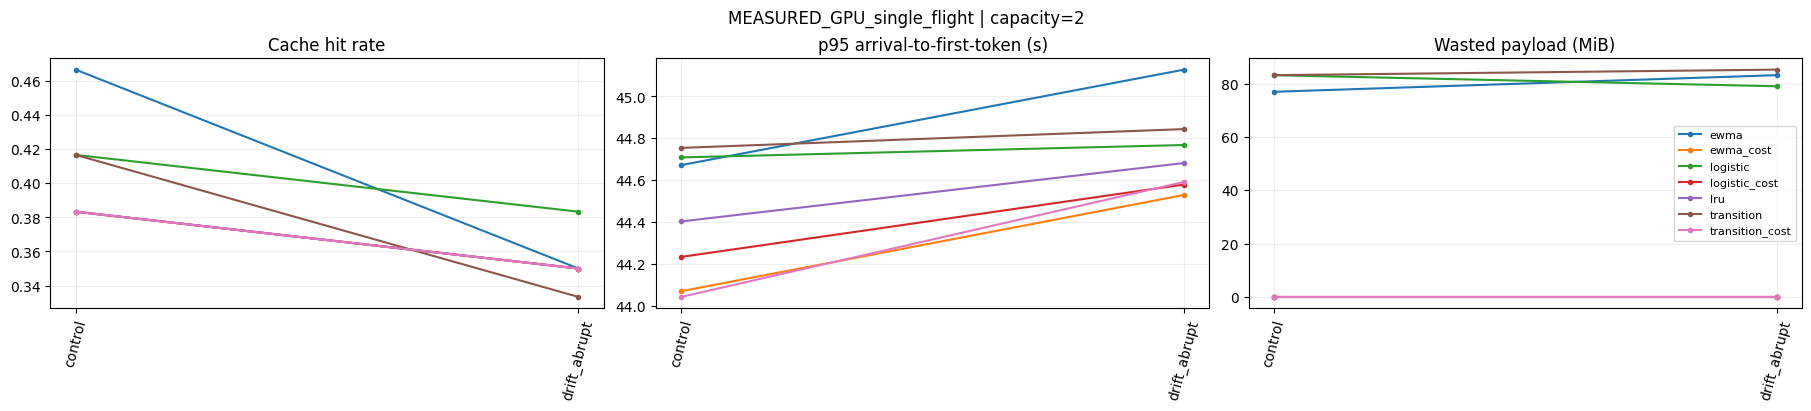

In [16]:
async def replay_gpu(engine,tr,policy,capacity,costs,sizes):
    await rpc_one(engine,'reset')
    ctrl=Controller(policy,N_ADAPTERS); rows=[]; all_events=[]
    speculative=set(); useful=0; wasted=0; prefetches=0; transfer=0; evictions=0
    def ingest(events):
        nonlocal wasted,prefetches,transfer,evictions
        for event in events:
            a=event['adapter_id']-1
            for victim_id in event['evicted_ids']:
                victim=victim_id-1; evictions+=1
                if victim in speculative:
                    speculative.remove(victim); wasted+=int(sizes[victim])
            transfer+=event['payload_bytes']
            if event['phase']=='prefetch': speculative.add(a); prefetches+=1
            all_events.append(event)
    start=time.perf_counter()
    for r in tr.itertuples(index=False):
        target=start+float(r.timestamp_s)
        # No arrival times are compressed to catch up when the service is busy.
        delay=target-time.perf_counter()
        if delay>0: await asyncio.sleep(delay)
        before=await rpc_one(engine)
        ingest(before['events'])
        hit=r.adapter+1 in before['gpu_order_ids']
        if hit and r.adapter in speculative:
            speculative.remove(r.adapter); useful+=1
        observed=time.perf_counter()-start
        ctrl.observe(r.adapter,observed)
        result=await consume(engine,r.adapter,f'{policy}_{r.request_id}_{time.perf_counter_ns()}')
        after=await rpc_one(engine); ingest(after['events'])
        if not hit:
            assert any(e['adapter_id']==r.adapter+1 for e in after['events']), 'Miss had no worker activation event.'
        a=ctrl.choose(time.perf_counter()-start,[i-1 for i in after['gpu_order_ids']],capacity,costs,sizes)
        if a is not None:
            pref=await rpc_one(engine,'prefetch',a+1); ingest(pref['events'])
            assert a+1 in pref['gpu_order_ids'], 'Prefetch did not become GPU resident.'
        rows.append(dict(request_id=r.request_id,adapter=r.adapter,phase=r.phase,
            timestamp_s=r.timestamp_s,hit=hit,queue_s=result['submitted']-target,
            ttft_s=result['first']-target,service_ttft_s=result['first']-result['submitted'],
            response_s=result['ended']-target,output_tokens=result['output_tokens']))
    requests=pd.DataFrame(rows)
    stats=dict(backend='gpu_single_flight',policy=policy,capacity=capacity,
               **summarize_requests(requests),prefetches=prefetches,useful_prefetches=useful,
               useful_prefetch_rate=useful/prefetches if prefetches else np.nan,
               wasted_bytes_evicted=wasted,unused_bytes_end=int(sum(sizes[a] for a in speculative)),
               wasted_bytes_total=wasted+int(sum(sizes[a] for a in speculative)),
               transfer_bytes=transfer,evictions=evictions)
    return stats,requests,pd.DataFrame(all_events),pd.DataFrame(ctrl.logs)

async def run_gpu_suite():
    selected=list(SCENARIOS) if PROFILE=='full' else ['control', 'drift_abrupt']
    manifest=json.loads((ROOT/'environment.json').read_text())
    fingerprint=hashlib.sha256(json.dumps(manifest,sort_keys=True).encode()).hexdigest()
    results=[]; rng=np.random.default_rng(2026)
    for cap in CAPACITIES:
        engine=await start_engine(cap)
        try:
            await gpu_preflight(engine,cap)
            calibration,costs,sizes=await calibrate(engine)
            calibration.to_csv(ROOT/'gpu'/f'calibration_c{cap}.csv',index=False)
            assert np.all(costs>0) and np.all(sizes>0)
            for scenario in selected:
                for seed in SEEDS:
                    tr=TRACES[scenario,seed]
                    # Random policy order reduces systematic thermal/order bias.
                    for policy in rng.permutation(POLICIES):
                        stem=f'{scenario}_s{seed}_c{cap}_{policy}'
                        stats_path=ROOT/'gpu'/f'{stem}_stats.json'
                        trace_hash=hashlib.sha256(tr.to_csv(index=False).encode()).hexdigest()
                        run_hash=hashlib.sha256((fingerprint+trace_hash).encode()).hexdigest()
                        if stats_path.exists():
                            stats=json.loads(stats_path.read_text())
                            if stats.get('fingerprint')!=run_hash:
                                raise RuntimeError('Existing run configuration changed; use a new ROOT: '+stem)
                            results.append(stats); continue
                        print('GPU run:',stem,flush=True)
                        stats,req,ev,dec=await replay_gpu(engine,tr,policy,cap,costs,sizes)
                        stats.update(scenario=scenario,seed=seed,fingerprint=run_hash)
                        req.to_csv(ROOT/'gpu'/f'{stem}_requests.csv',index=False)
                        ev.to_csv(ROOT/'gpu'/f'{stem}_events.csv',index=False)
                        dec.to_csv(ROOT/'gpu'/f'{stem}_decisions.csv',index=False)
                        stats_path.write_text(json.dumps(stats,indent=2))
                        results.append(stats)
                        pd.DataFrame(results).to_csv(ROOT/'gpu'/'summary.csv',index=False)
        finally:
            await stop_engine(engine)
    return pd.DataFrame(results)

if RUN_GPU:
    # Jupyter/Colab supports top-level await; do not use asyncio.run here.
    gpu_results=await run_gpu_suite()
    display(gpu_results)
    paired_comparisons(gpu_results).to_csv(ROOT/'gpu'/'paired_p95.csv',index=False)
    plot_results(gpu_results,'MEASURED_GPU_single_flight',ROOT/'figures')
    recovery=[]
    for row in gpu_results.itertuples(index=False):
        if not SCENARIOS[row.scenario].get('drift_severity'): continue
        stem=f'{row.scenario}_s{row.seed}_c{row.capacity}_{row.policy}'
        req=pd.read_csv(ROOT/'gpu'/f'{stem}_requests.csv')
        recovery.append(dict(scenario=row.scenario,seed=row.seed,capacity=row.capacity,policy=row.policy,
            **drift_recovery(req,TRACES[row.scenario,row.seed],SCENARIOS[row.scenario].get('drift_width',0))))
    pd.DataFrame(recovery).to_csv(ROOT/'gpu'/'drift_recovery.csv',index=False)
else:
    print('No GPU measurements performed. Simulation results must not be reported as measured TTFT.')

In [17]:
# Small held-out development sweep (not included in the main seed summaries).
dev=make_trace(n=300,seed=9001,drift_severity=1.)
sensitivity=[]
for horizon in [.25,1.,3.]:
    for threshold in [.35,.55,.75]:
        cfg=replace(CFG,horizon_s=horizon,min_probability=threshold)
        for policy in ['ewma_cost','transition_cost','logistic_cost']:
            st,*_=simulate(dev,policy,capacity=2,cfg=cfg)
            sensitivity.append(dict(horizon_s=horizon,threshold=threshold,**st))
pd.DataFrame(sensitivity).to_csv(ROOT/'simulation'/'development_sensitivity.csv',index=False)

# A manifest records assumed simulator parameters as well as measured environment.
simulation_manifest=dict(backend='simulation',model_assumptions=dict(load_s=SIM_LOAD_S,
    first_token_s=SIM_FIRST_S,response_s=SIM_RESPONSE_S,adapter_bytes=SIM_BYTES.tolist()),
    policy_config=asdict(CFG),profile=PROFILE,seeds=SEEDS,requests=N_REQUESTS,scenarios=SCENARIOS)
(ROOT/'simulation'/'manifest.json').write_text(json.dumps(simulation_manifest,indent=2))

# Generate compact paired tables without making up a positive result.
report_source=gpu_results if RUN_GPU else sim_results
report_label='MEASURED GPU, single-flight' if RUN_GPU else 'SIMULATION, assumed costs'
comparison=paired_comparisons(report_source)
comparison.to_csv(ROOT/('presentation_comparison_gpu.csv' if RUN_GPU else 'presentation_comparison_simulation.csv'),index=False)
print(report_label)
display(comparison[comparison.policy!='lru'].sort_values('mean_delta').head(12).round(5))

import shutil
archive=shutil.make_archive(str(ROOT.parent/(ROOT.name+'_results')),'zip',root_dir=ROOT)
print('Result bundle:',archive)

MEASURED GPU, single-flight


,scenario,capacity,policy,metric,n_seeds,mean_delta,ci_low,ci_high,mean_relative_percent
6,control,2,transition_cost,ttft_p95_s,1,-0.36068,-0.36068,-0.36068,-0.81229
1,control,2,ewma_cost,ttft_p95_s,1,-0.33328,-0.33328,-0.33328,-0.75060
3,control,2,logistic_cost,ttft_p95_s,1,-0.16948,-0.16948,-0.16948,-0.38169
8,drift_abrupt,2,ewma_cost,ttft_p95_s,1,-0.15254,-0.15254,-0.15254,-0.34138
10,drift_abrupt,2,logistic_cost,ttft_p95_s,1,-0.10274,-0.10274,-0.10274,-0.22995
13,drift_abrupt,2,transition_cost,ttft_p95_s,1,-0.09046,-0.09046,-0.09046,-0.20246
9,drift_abrupt,2,logistic,ttft_p95_s,1,0.08604,0.08604,0.08604,0.19256
12,drift_abrupt,2,transition,ttft_p95_s,1,0.16201,0.16201,0.16201,0.36260
0,control,2,ewma,ttft_p95_s,1,0.26906,0.26906,0.26906,0.60595
2,control,2,logistic,ttft_p95_s,1,0.30583,0.30583,0.30583,0.68877


Result bundle: /content/lora_cache_project_results.zip


In [18]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

checkpoint = Path("/content/drive/MyDrive/LoRA_Cache_Project/checkpoint")
shutil.copytree(ROOT, checkpoint, dirs_exist_ok=True)

print("Progress saved:", checkpoint)
print("Completed GPU runs:", len(list((checkpoint / "gpu").glob("*_stats.json"))))

Mounted at /content/drive
Progress saved: /content/drive/MyDrive/LoRA_Cache_Project/checkpoint
Completed GPU runs: 14


In [19]:
# Recover completed GPU runs from saved files.
if RUN_GPU:
    saved_files = sorted((ROOT / "gpu").glob("*_stats.json"))

    if not saved_files:
        raise RuntimeError(
            "No completed GPU runs found in this ROOT. "
            "Check that ROOT points to your experiment folder."
        )

    gpu_results = pd.DataFrame([
        json.loads(path.read_text()) for path in saved_files
    ])
    report_source = gpu_results
    report_label = "MEASURED GPU, single-flight — saved runs; may be partial"
    suffix = "gpu_partial"
else:
    report_source = sim_results
    report_label = "SIMULATION, assumed costs"
    suffix = "simulation"

print(report_label)
print("Saved runs:", len(report_source))

report_source.to_csv(
    ROOT / f"presentation_saved_runs_{suffix}.csv",
    index=False,
)

# Compare only groups that have a matching LRU baseline.
keys = ["scenario", "seed", "capacity"]
baseline_keys = (
    report_source.loc[report_source["policy"] == "lru", keys]
    .drop_duplicates()
)

paired_source = report_source.merge(
    baseline_keys,
    on=keys,
    how="inner",
    validate="many_to_one",
)

excluded = len(report_source) - len(paired_source)
print("Runs excluded because their LRU baseline is missing:", excluded)

if not paired_source.empty:
    comparison = paired_comparisons(paired_source)
    comparison.to_csv(
        ROOT / f"presentation_comparison_{suffix}.csv",
        index=False,
    )
    display(
        comparison[comparison["policy"] != "lru"]
        .sort_values("mean_delta")
        .head(12)
        .round(5)
    )
else:
    print("No matched LRU comparisons yet. Raw results were exported.")

import shutil

archive = shutil.make_archive(
    str(ROOT.parent / (ROOT.name + "_results")),
    "zip",
    root_dir=ROOT,
)
print("Result bundle:", archive)

MEASURED GPU, single-flight — saved runs; may be partial
Saved runs: 14
Runs excluded because their LRU baseline is missing: 0


,scenario,capacity,policy,metric,n_seeds,mean_delta,ci_low,ci_high,mean_relative_percent
6,control,2,transition_cost,ttft_p95_s,1,-0.36068,-0.36068,-0.36068,-0.81229
1,control,2,ewma_cost,ttft_p95_s,1,-0.33328,-0.33328,-0.33328,-0.75060
3,control,2,logistic_cost,ttft_p95_s,1,-0.16948,-0.16948,-0.16948,-0.38169
8,drift_abrupt,2,ewma_cost,ttft_p95_s,1,-0.15254,-0.15254,-0.15254,-0.34138
10,drift_abrupt,2,logistic_cost,ttft_p95_s,1,-0.10274,-0.10274,-0.10274,-0.22995
13,drift_abrupt,2,transition_cost,ttft_p95_s,1,-0.09046,-0.09046,-0.09046,-0.20246
9,drift_abrupt,2,logistic,ttft_p95_s,1,0.08604,0.08604,0.08604,0.19256
12,drift_abrupt,2,transition,ttft_p95_s,1,0.16201,0.16201,0.16201,0.36260
0,control,2,ewma,ttft_p95_s,1,0.26906,0.26906,0.26906,0.60595
2,control,2,logistic,ttft_p95_s,1,0.30583,0.30583,0.30583,0.68877


Result bundle: /content/lora_cache_project_results.zip
